In [2]:
import random
import soundfile as sf  

# imports
import pandas as pd
import numpy as np
import librosa
from pathlib import Path
from scipy.fft import rfft
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy
from scipy import signal
import noisereduce as nr
import math 
import os
import cv2
import regex as re 
from datetime import datetime
from tqdm.notebook import tqdm

import shutil

### Replace the following path with the one from your machine - ONLY if you need to re run

In [3]:
root_path = Path(r"C:\Users\Felic\Remote Sensing\Research\5891 Final Project\Data - Time Series")

In [4]:
files_list = []
for root in root_path.iterdir():
    for folder in root.iterdir():
        if folder.is_dir():
            files = [f for f in folder.iterdir() if f.is_file()]

            if len(files) == 0:
                print(f"No files in {folder}")
                continue
            for f in files:
                match = re.search(r"\.(\d{12})", f.name)
                dt = datetime.strptime(match.group(1), "%y%m%d%H%M%S")
                files_list.append([str(f), dt])
df = pd.DataFrame(files_list, columns=["filepath","datetime"])       
df

,filepath,datetime
0,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:00:24
1,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:10:24
2,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:20:24
3,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:30:24
4,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:40:24
...,...,...
44419,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:16:15
44420,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:26:15
44421,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:36:15
44422,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:46:15


In [5]:
# df.to_csv("audio_data.csv")

## Setting audio Parameters

In [5]:
sample_rate = 1024
n_fft=256
hop_length=128

In [6]:
def load_and_resample(path, target_sr=sample_rate):
    y, sr = librosa.load(path, sr = target_sr)
    return y, target_sr

def spectrogram_encode(y, sr = sample_rate):
    S = np.abs(librosa.stft(
        y,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=n_fft,
        window='hann',
        center=True,
        pad_mode='constant'
    ))
    return np.log1p(S).T  # log compression

# Acoustic Feature Dictionary

## Energy Features
These describe the overall intensity or acoustic activity of the recording.

| Variable | Description |
|-----------|-------------|
| `min_energy` | Lowest frame-level energy observed during the recording. |
| `q25_energy` | 25th percentile of frame energy; represents quieter periods while being less sensitive to outliers than the minimum. |
| `median_energy` | Typical frame energy across the recording. |
| `mean_energy` | Average energy across all frames; a measure of overall acoustic activity. |
| `std_energy` | Variability in energy over time; higher values indicate more fluctuations or transient events. |
| `q75_energy` | 75th percentile of frame energy; represents moderately active periods. |
| `max_energy` | Highest frame-level energy observed; often corresponds to the strongest acoustic event. |
| `p95_energy` | 95th percentile of frame energy; captures strong events without being dominated by a single extreme value. |

## Spectral Centroid Features
These describe where the "center of mass" of the spectrum lies, indicating whether energy is concentrated at lower or higher frequencies.

| Variable | Description |
|-----------|-------------|
| `min_centroid` | Lowest spectral centroid observed during the recording. |
| `q25_centroid` | Lower quartile of spectral centroid values. |
| `median_centroid` | Typical spectral centroid for the recording. |
| `mean_centroid` | Average spectral centroid; higher values indicate a generally higher-frequency soundscape. |
| `std_centroid` | Variability in the spectral centroid over time. |
| `q75_centroid` | Upper quartile of spectral centroid values. |
| `max_centroid` | Highest spectral centroid observed. |
| `p95_centroid` | 95th percentile of spectral centroid values; represents periods with unusually high-frequency energy. |

## Spectral Entropy Features
These describe how concentrated or dispersed spectral energy is.

| Variable | Description |
|-----------|-------------|
| `min_entropy` | Most tonal or least complex frame observed. |
| `q25_entropy` | Lower quartile of entropy values. |
| `median_entropy` | Typical spectral entropy for the recording. |
| `mean_entropy` | Average entropy; lower values indicate more structured sound, while higher values indicate more noise-like sound. |
| `std_entropy` | Variability in spectral complexity over time. |
| `q75_entropy` | Upper quartile of entropy values. |
| `max_entropy` | Most broadband or noise-like frame observed. |
| `p95_entropy` | 95th percentile of entropy values; characterizes highly complex portions of the recording. |

## Temporal Activity Feature

| Variable | Description |
|-----------|-------------|
| `activity_fraction` | Proportion of frames classified as highly active based on an energy threshold. Measures how often notable acoustic activity occurs during the recording. |

## Frequency Band Features
These describe how acoustic energy is distributed across frequency ranges.

| Variable | Description |
|-----------|-------------|
| `band_0_20` | Fraction of total recording energy contained between 0–20 Hz. |
| `band_20_50` | Fraction of total recording energy contained between 20–50 Hz. |
| `band_50_100` | Fraction of total recording energy contained between 50–100 Hz. |
| `band_100_200` | Fraction of total recording energy contained between 100–200 Hz. |

## Interpretation Guide

- **High energy** → louder or more acoustically active soundscape.
- **High centroid** → more energy concentrated at higher frequencies.
- **High entropy** → more broadband, noise-like sound.
- **Low entropy** → more tonal or structured sound.
- **High activity fraction** → acoustic events occur frequently throughout the recording.
- **Band energy ratios** → indicate where acoustic energy is concentrated and can reveal environmental, seasonal, weather-related, or biological patterns.

### Potential Ecological Interpretation

- Increased low-frequency energy may be associated with wave action, wind, currents, vessel activity, or low-frequency biological sounds.
- Shifts in spectral centroid may indicate changes in the dominant sound sources present.
- Changes in entropy may indicate transitions between organized biological choruses and broadband environmental noise.
- Increased activity fraction may indicate periods of heightened biological or environmental activity.

# Creating the features

In [7]:
import numpy as np
from scipy.stats import entropy
import librosa


def calculate_frame_energy(X):
    """
    Calculate energy for each spectrogram frame.

    Parameters
    ----------
    X : np.ndarray
        Spectrogram of shape [time_frames, frequency_bins].

    Returns
    -------
    np.ndarray
        Energy value for each frame.
    """
    energy_values = np.sum(X**2, axis=1)
    return energy_values


def calculate_spectral_centroid(X):
    """
    Calculate spectral centroid for each frame.

    The spectral centroid represents the frequency "center of mass"
    and is often interpreted as the average frequency present.

    Returns
    -------
    np.ndarray
        Spectral centroid for each frame in Hz.
    """
    freqs = librosa.fft_frequencies(sr=sample_rate, n_fft=n_fft)

    return np.sum(X * freqs, axis=1)/ np.maximum(np.sum(X, axis=1), 1e-12)


def calculate_band_energy_ratios(X):
    """
    Calculate the fraction of total energy located within
    predefined frequency bands.

    Returns
    -------
    dict
        Energy fractions by frequency band.
    """
    freqs = librosa.fft_frequencies(sr=sample_rate, n_fft=n_fft)

    power = X**2
    total_energy = np.sum(power)

    bands = {
        "band_0_20": (0, 20),
        "band_20_50": (20, 50),
        "band_50_100": (50, 100),
        "band_100_200": (100, 200),
    }

    results = {}

    for name, (low, high) in bands.items():
        mask = (freqs >= low) & (freqs < high)

        results[name] = (np.sum(power[:, mask]) / total_energy if total_energy > 0 else 0)

    return results


def calculate_spectral_entropy(X):
    """
    Calculate spectral entropy for each frame.

    Lower values indicate concentrated tonal energy.
    Higher values indicate broadband noise.

    Returns
    -------
    np.ndarray
        Spectral entropy values.
    """
    probabilities = X / np.maximum(X.sum(axis=1, keepdims=True),1e-12)

    return np.array([entropy(row)for row in probabilities])

def summarize_array(values, prefix):
    """
    Create common summary statistics for a 1D array.

    Parameters
    ----------
    values : np.ndarray
        Array of values to summarize.

    prefix : str
        Prefix to prepend to feature names.

    Returns
    -------
    dict
        Dictionary of summary statistics.
    """
    return {
        f"min_{prefix}": np.min(values),
        f"q25_{prefix}": np.percentile(values, 25),
        f"median_{prefix}": np.median(values),
        f"mean_{prefix}": np.mean(values),
        f"std_{prefix}": np.std(values),
        f"q75_{prefix}": np.percentile(values, 75),
        f"max_{prefix}": np.max(values),
        f"p95_{prefix}": np.percentile(values, 95),
    }

def summarize_recording(X):
    """
    Generate a feature vector describing an entire recording.

    Parameters
    ----------
    X : np.ndarray
        Spectrogram with shape [time_frames, frequency_bins].

    sr : int
        Sample rate.

    n_fft : int
        FFT window size.

    Returns
    -------
    dict
        Recording-level summary statistics.
    """

    energy = calculate_frame_energy(X)
    centroid = calculate_spectral_centroid(X)
    entropy_vals = calculate_spectral_entropy(X)

    features = {}

    features.update(
        summarize_array(energy, "energy")
    )

    features.update(
        summarize_array(centroid, "centroid")
    )

    features.update(
        summarize_array(entropy_vals, "entropy")
    )

    features["activity_fraction"] = np.mean(
        energy > np.percentile(energy, 90)
    )

    features.update(
        calculate_band_energy_ratios(X)
    )

    return features


In [8]:
rows = []
for i in tqdm(range(len(df)), desc="Processing recordings"):
    y, _ = load_and_resample(df["filepath"][i])
    X = spectrogram_encode(y)
    X = X[30:,:] # Cutting first 30 frames of startup noise
    rows.append(summarize_recording(X))
    del X, y
rows_df = pd.DataFrame(rows)

Processing recordings:   0%|          | 0/44424 [00:00<?, ?it/s]

In [9]:
# rows_df.to_csv("desc_data.csv")

In [11]:
df_final = pd.concat([df, rows_df], axis=1)
df_final

,filepath,datetime,min_energy,q25_energy,median_energy,mean_energy,std_energy,q75_energy,max_energy,p95_energy,...,mean_entropy,std_entropy,q75_entropy,max_entropy,p95_entropy,activity_fraction,band_0_20,band_20_50,band_50_100,band_100_200
0,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:00:24,0.030359,0.031062,0.031174,0.031284,0.000472,0.031331,0.036236,0.032085,...,1.883757,0.092443,1.933904,2.490637,2.042316,0.100108,0.998840,0.000284,0.000199,0.000183
1,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:10:24,0.030608,0.031059,0.031189,0.031313,0.000503,0.031367,0.036422,0.032148,...,1.832476,0.086873,1.873424,2.425258,1.974610,0.100108,0.998968,0.000258,0.000190,0.000158
2,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:20:24,0.017815,0.030993,0.031140,0.031255,0.000681,0.031344,0.036300,0.032154,...,1.832656,0.099988,1.874171,3.463631,1.982613,0.100000,0.998941,0.000290,0.000189,0.000157
3,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:30:24,0.016117,0.031037,0.031156,0.031249,0.000688,0.031322,0.036244,0.031957,...,1.908248,0.092778,1.952452,3.460145,2.039297,0.100000,0.998748,0.000324,0.000210,0.000179
4,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2019-05-16 00:40:24,0.029392,0.031146,0.031251,0.031373,0.000479,0.031423,0.036242,0.032148,...,2.061423,0.092924,2.117339,2.692988,2.218493,0.100000,0.998246,0.000412,0.000289,0.000253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44419,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:16:15,1.194980,1.224293,1.225432,1.224910,0.002406,1.226196,1.228194,1.227187,...,1.131074,0.100938,1.147901,3.064888,1.212329,0.100000,0.999851,0.000023,0.000059,0.000012
44420,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:26:15,1.217079,1.224570,1.225751,1.225143,0.001981,1.226360,1.227758,1.227138,...,1.187711,0.045477,1.210217,1.450259,1.269474,0.100223,0.999839,0.000005,0.000069,0.000007
44421,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:36:15,1.216133,1.224637,1.225744,1.225159,0.002044,1.226464,1.228583,1.227043,...,1.076708,0.030918,1.096164,1.203346,1.128200,0.100223,0.999905,0.000005,0.000054,0.000008
44422,C:\Users\Felic\Remote Sensing\Research\5891 Fi...,2020-03-26 23:46:15,1.216185,1.224429,1.225561,1.225007,0.002081,1.226351,1.228101,1.227251,...,1.043253,0.070491,1.060886,2.354381,1.099878,0.100223,0.999932,0.000010,0.000025,0.000008


In [13]:
# df_final.to_csv("final_description_data.csv", index = False)

# Plotting code if you want it

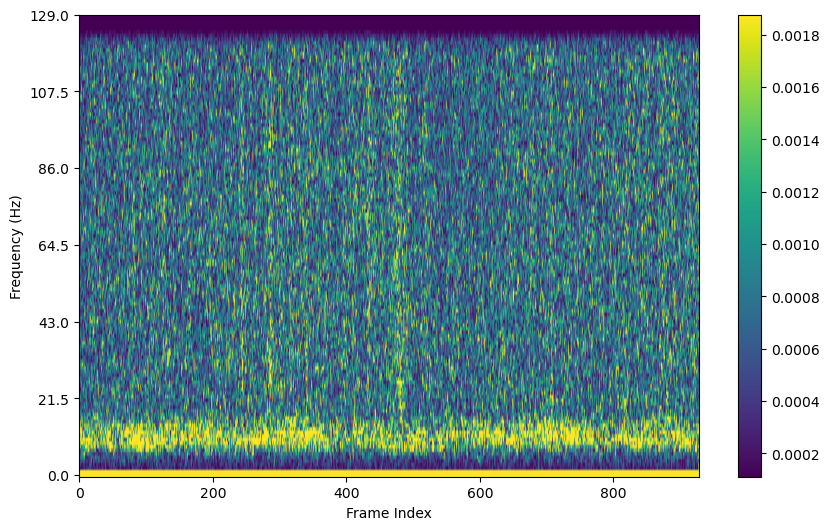

In [36]:
vmin = np.percentile(X, 5)
vmax = np.percentile(X, 95)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(
    X.T,
    aspect='auto',
    vmin=vmin,
    vmax=vmax,
    cmap='viridis'
)

ax.invert_yaxis()
ax.set_yticks(np.linspace(0, X.shape[1], 7))
ax.set_ylabel("Frequency (Hz)")
ax.set_xlabel("Frame Index")
plt.colorbar(im, ax=ax)
plt.show()